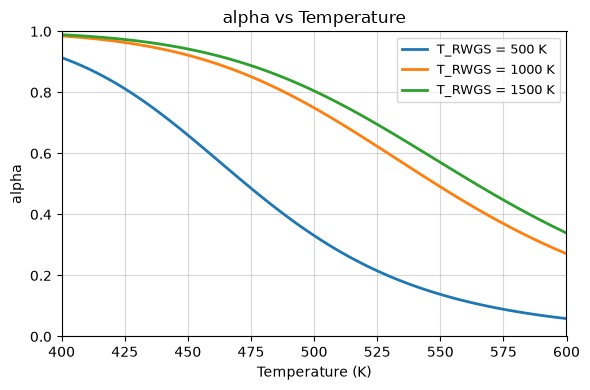

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def equilibrium_constant(T):
    K_eq = np.exp(-13.148 + 1.077 * np.log(T) + 5.44e-4 * T - 1.125e-7 * T**2 + 5693.5 / T - 49170 / T**2)
    return K_eq

def equilibrium_compositions(K_eq):
    molefr_CO = 1 / (2 * (1 + np.sqrt(K_eq)))
    molefr_CO2 = np.sqrt(K_eq) / (2 * (1 + np.sqrt(K_eq)))
    molefr_H2 = np.sqrt(K_eq) / (2 * (1 + np.sqrt(K_eq))) 
    return molefr_CO, molefr_CO2, molefr_H2

# Constants
k_o_sq = 0.113
dEA = -47554  # J/mol
T_ref = 500 
a = 1.027 
b = -0.303 
c = 0.038 
R = 8.314  # J/(mol·K)
P = 5e5  # Pa

# Reaction temperatures for which to calculate curves
T_RWGS = np.array([500, 1000, 1500])

# Temperature range for x-axis
T_FT = np.linspace(400, 600, 100)

plt.figure(figsize=(6, 4))

# Loop through each reaction temperature
for T_rxn in T_RWGS:
    # Calculate equilibrium constant at reaction temperature
    K_eq = equilibrium_constant(T_rxn)
    
    # Get equilibrium compositions
    molefr_CO, molefr_CO2, molefr_H2 = equilibrium_compositions(K_eq)
    
    # Calculate partial pressures
    P_CO = molefr_CO * P
    P_CO2 = molefr_CO2 * P
    P_H2 = molefr_H2 * P
    
    # Calculate concentrations
    C_CO = P_CO / (R * T_FT)
    C_CO2 = P_CO2 / (R * T_FT)
    C_H2 = P_H2 / (R * T_FT)
    
    # Calculate alpha for this reaction temperature
    α = (1 + (C_H2**c / (k_o_sq * np.exp((dEA / R) * ((1 / T_ref) - (1 / T_FT))) * (C_CO**a + C_CO2**b))))**-1
    
    # Plot curve for this reaction temperature
    plt.plot(T_FT, α, linewidth=2, label=f'T_RWGS = {T_rxn} K')

plt.xlabel('Temperature (K)', fontsize=10)
plt.ylabel('alpha', fontsize=10)
plt.title('alpha vs Temperature', fontsize=12)
plt.grid(True, alpha=0.5)
plt.xlim(400, 600)
plt.ylim(0, 1)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

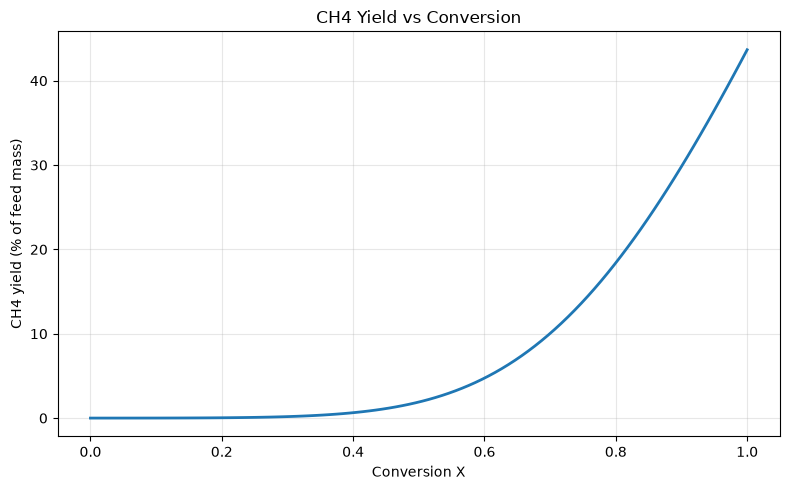

α = [0.98896352 0.98809311 0.98716437 0.98617419 0.98511937 0.98399659
 0.98280242 0.98153334 0.98018573 0.97875587 0.97723994 0.97563404
 0.97393419 0.97213631 0.97023628 0.96822988 0.96611286 0.96388092
 0.9615297  0.95905485 0.95645196 0.95371664 0.95084453 0.94783126
 0.94467252 0.94136404 0.93790164 0.93428123 0.93049882 0.92655055
 0.92243271 0.91814177 0.91367438 0.9090274  0.90419792 0.89918329
 0.89398113 0.88858938 0.88300625 0.87723034 0.87126056 0.86509624
 0.85873706 0.85218313 0.84543499 0.83849359 0.83136037 0.82403717
 0.81652634 0.80883068 0.80095345 0.79289839 0.78466971 0.77627207
 0.76771059 0.75899082 0.75011875 0.74110078 0.73194369 0.72265466
 0.71324118 0.70371109 0.69407251 0.68433385 0.67450371 0.66459095
 0.65460454 0.64455364 0.63444748 0.62429536 0.61410662 0.60389061
 0.59365661 0.58341387 0.57317153 0.56293859 0.55272389 0.54253609
 0.53238366 0.52227479 0.51221744 0.5022193  0.49228774 0.48242984
 0.47265234 0.46296166 0.45336387 0.44386469 0.43446948 0.

TypeError: unsupported format string passed to numpy.ndarray.__format__

In [3]:
import numpy as np
import matplotlib.pyplot as plt

X = np.linspace(0, 1, 100)  # conversion from 0 to 1

# methane fraction: n=1
w_ch4 = (1 - α) ** 2

# methane yield vs conversion
yield_ch4 = X * w_ch4
yield_ch4_percent = 100 * yield_ch4

plt.figure(figsize=(8, 5))
plt.plot(X, yield_ch4_percent, color='tab:blue', linewidth=2)
plt.xlabel("Conversion X")
plt.ylabel("CH4 yield (% of feed mass)")
plt.title(f"CH4 Yield vs Conversion")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"α = {α}")
print(f"w_CH4 = {w_ch4:.6f}")
print(f"CH4 yield formula = {w_ch4:.6f} * X")
print(f"CH4 yield at X=0.8 = {100*w_ch4*0.8:.3f}%")